In [71]:
import pandas as pd
pd.set_option('display.max_rows',None)
pd.set_option('display.max_colwidth',None)

In [2]:
pd.set_option('display.max_rows',10)


### Dataset Import

In [3]:
!pip install plotly


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import  plotly.graph_objects as go

In [5]:
data = pd.read_csv("Dataset/gurgaon-properties-missingValue-removed.csv")
data.head(10)

,property_name,property_type,society,sector,area,price,price_per_sqft,Plot area,Super Built Up area,Built Up area,...,TV,Washing Machine,Bed,AC,Light,Fan,Exhaust Fan,Modular Kitchen,furnishing_type,luxury score
0,3 BHK Flat in Sector-33 Sohna,flat,Central Park Flower Valley Aqua Front Towers,Sector-33 Sohna,1789.10,1.700,9502.0,0.00,1788.96,1781.139,...,0,0,0,2,1,1,0,0,0,33
1,3 BHK Flat in Sector 84 Gurgaon,flat,Antriksh Heights,Sector 84 Gurgaon,1350.00,0.945,7000.0,0.00,1350.01,1344.108,...,0,0,0,0,20,6,1,1,2,98
2,5 Bedroom House for sale in Jacobpura,house,Jacobpura,Jacobpura,2002.09,1.700,8000.0,0.00,0.00,2000.040,...,0,0,0,0,0,0,0,0,0,9
3,3 BHK Flat in Sector 77 Gurgaon,flat,Emaar Palm Premier,Sector 77 Gurgaon,2000.00,2.100,10500.0,0.00,2000.04,1599.950,...,0,0,0,0,10,0,1,1,2,138
4,2 BHK Flat in Sector 65 Gurgaon,flat,M3M Heights,Sector 65 Gurgaon,1261.03,2.100,16653.0,0.00,1260.99,1117.577,...,0,0,0,4,6,6,0,0,0,40
5,2 BHK Flat in Sector 79 Gurgaon,flat,Supertech Basera,Sector 79 Gurgaon,471.02,0.360,7643.0,0.00,0.00,546.050,...,0,0,0,0,0,0,0,0,0,69
6,3 BHK Flat in Sector 107 Gurgaon,flat,M3M Woodshire,Sector 107 Gurgaon,1202.03,1.300,10815.0,0.00,1942.99,1703.257,...,0,0,0,0,0,0,0,0,0,98
7,6 Bedroom House for sale in Saraswati Vihar,house,Housing Board Colony,Saraswati Vihar,1345.49,3.500,25926.0,1350.01,0.00,1345.490,...,0,0,0,0,0,0,0,0,0,0
8,"2 Bedroom House for sale in Mahalaxmi Garden, Rajendra Place",house,"Mahalaxmi Garden, Rajendra Place","Mahalaxmi Garden, Rajendra Place",452.08,0.380,8444.0,450.04,0.00,452.080,...,0,0,0,0,0,0,0,0,0,0
9,1 Bedroom House for sale in Mianwali Colony,house,Project Mianwali Colony,Mianwali Colony,1797.57,1.700,9444.0,0.00,0.00,2204.416,...,0,0,0,0,0,0,0,0,0,0


dropping  
1.           price per sqft because if user knows this val then it can find total price also 
2.           society name , bacause for specific society he can just go and look for that 
    Therefore,unnecessary col

In [6]:
data.drop(columns=['society','price_per_sqft','Plot area','Super Built Up area','Carpet area','area','Dining Table', 'Curtains',
       'Sofa', 'Water Purifier', 'Chimney', 'Geyser', 'Wardrobe', 'Fridge',
       'Microwave', 'Stove', 'TV', 'Washing Machine', 'Bed', 'AC', 'Light',
       'Fan', 'Exhaust Fan', 'Modular Kitchen','rating','facing','description','address'],inplace=True,errors='ignore')
data.shape

(934, 17)

In [7]:
data.columns

Index(['property_name', 'property_type', 'sector', 'price', 'Built Up area',
       'bedRoom', 'bathroom', 'balcony', 'floorNum', 'agePossession',
       'Study Room', 'Pooja Room', 'Servant Room', 'Store Room', 'Others',
       'furnishing_type', 'luxury score'],
      dtype='object')

In [8]:
dt = data.copy()
dt.isnull().sum()

property_name      0
property_type      0
sector             0
price              0
Built Up area      0
                  ..
Servant Room       0
Store Room         0
Others             0
furnishing_type    0
luxury score       0
Length: 17, dtype: int64

### luxury score
since i can not ask luxury score about customer , this feature is created by us - therefore let us divide it into  category - budget ,semi-budget,luxurious

<Axes: xlabel='luxury score'>

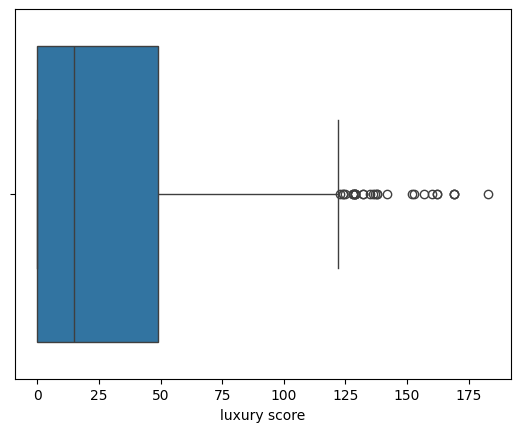

In [9]:
sns.boxplot(x=dt['luxury score'])

<Axes: xlabel='luxury score', ylabel='price'>

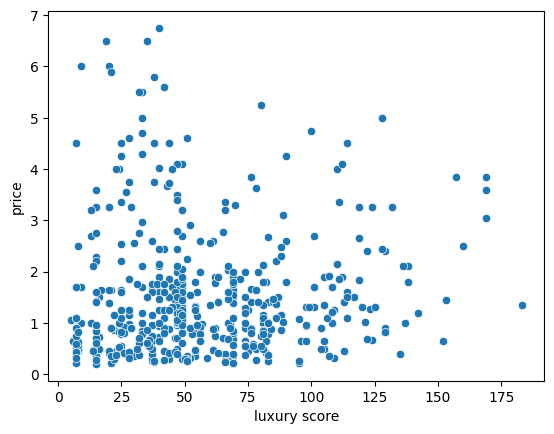

In [10]:
x = dt[(dt['price']<8) & (dt['luxury score']!=0)]
sns.scatterplot(x,x='luxury score',y ='price')

In [11]:
def categorize_luxury(x):
    if x<50:
        return "Low"
    elif x<140:
        return 'Medium'
    else :
        return 'High'

dt['categorized luxury'] =dt['luxury score'].apply(categorize_luxury)
    

<Axes: ylabel='categorized luxury'>

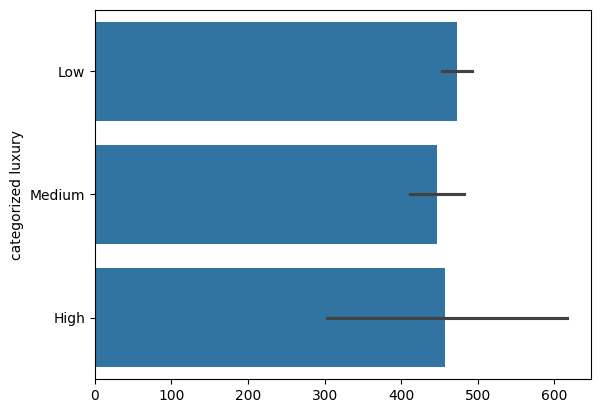

In [12]:
sns.barplot(dt['categorized luxury'] )

In [13]:
dt.groupby('categorized luxury')['price'].agg(['mean','median','min','max'])
#some properties with low luxury are high due to nearby facility and demand

,mean,median,min,max
categorized luxury,,,,
High,3.859091,3.05,0.650,10.50
Low,1.762281,1.10,0.075,13.00
Medium,1.486946,1.25,0.220,10.55


In [14]:
def categorize_floor(x):
    if x<4:
        return "Low Rise"
    elif x<10:
        return 'Medium Rise'
    else :
        return 'High Rise'

dt['floor'] =dt['floorNum'].apply(categorize_floor)
    

<Axes: ylabel='floor'>

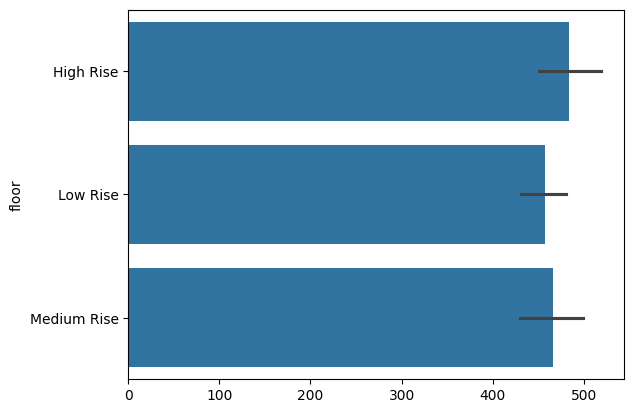

In [15]:
sns.barplot(dt['floor'] )


In [16]:
dt.groupby('floor')['price'].agg(['mean','median','min','max'])
#some properties with low luxury are high due to nearby facility and demand

,mean,median,min,max
floor,,,,
High Rise,1.631392,1.25,0.240,8.5
Low Rise,1.872494,1.15,0.075,13.0
Medium Rise,1.530379,1.10,0.200,12.0


Low rise is generally costlier 

In [17]:
dt.drop(columns=['floorNum','luxury score'],inplace=True)

In [18]:
df = dt.drop(columns = 'property_name')

### Preprocessing

In [19]:
from sklearn.preprocessing import OrdinalEncoder
cat = df.select_dtypes(include='object').columns
cat

Index(['property_type', 'sector', 'bathroom', 'balcony', 'agePossession',
       'categorized luxury', 'floor'],
      dtype='object')

In [20]:
# Apply label encoding to categorical columns
for i in cat:
    if ( i=='property_name'):
        continue
    oe = OrdinalEncoder()
    df[i] = oe.fit_transform(df[[i]])
    print(i,oe.categories_)
    
    

property_type [array(['flat', 'house'], dtype=object)]
sector [array(['A Block Sushant Lok Phase 1', 'Acharya Puri', 'Ambience Island',
       'Anand Garden, Sector-105', 'Ansal Plaza', 'Arjun Nagar',
       'Ashok Vihar', 'Ashok Vihar Phase 2', 'Ashok Vihar Phase 3',
       'Ashok Vihar Phase 3 Extension', 'Baldev Nagar', 'Bhawani Enclave',
       'Bhim Nagar', 'Bhondsi', 'Bhora Kalan', 'Bissar',
       'C Block Sushant Lok Phase 1', 'Chakkarpur', 'Civil L',
       'DLF Phase 1', 'DLF Phase 2', 'DLF Phase 3', 'DLF Phase 4',
       'DLF Phase 5', 'Dayanand Colony', 'Devilal Colony',
       'Dwarka Expressway Gurgaon', 'Farukhnagar', 'Garauli Kalan',
       'Garhi Harsaru', 'Golf Course Ext Road', 'Gurgaon Faridabad Road',
       'Gurgaon, Delhi NCR', 'Gwal Pahari', 'Heritage City', 'Hira Nagar',
       'Hno 13 Sagar enclave Sura', 'IFFCO Chowk', 'IMT Manesar',
       'Jacobpura', 'Jyoti Park', 'Khandsa', 'Krishna Colony',
       'Laxman Vihar', 'Laxman Vihar Phase 2', 'Laxmi Garden', '

In [21]:
# Splitting the dataset into training and testing sets
x_label = df.drop('price', axis=1)
y_label = df['price']

### Technique-1: Correlation Analysis

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 934 entries, 0 to 933
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   property_type       934 non-null    float64
 1   sector              934 non-null    float64
 2   price               934 non-null    float64
 3   Built Up area       934 non-null    float64
 4   bedRoom             934 non-null    int64  
 5   bathroom            934 non-null    float64
 6   balcony             934 non-null    float64
 7   agePossession       934 non-null    float64
 8   Study Room          934 non-null    int64  
 9   Pooja Room          934 non-null    int64  
 10  Servant Room        934 non-null    int64  
 11  Store Room          934 non-null    int64  
 12  Others              934 non-null    int64  
 13  furnishing_type     934 non-null    int64  
 14  categorized luxury  934 non-null    float64
 15  floor               934 non-null    float64
dtypes: float

<Axes: >

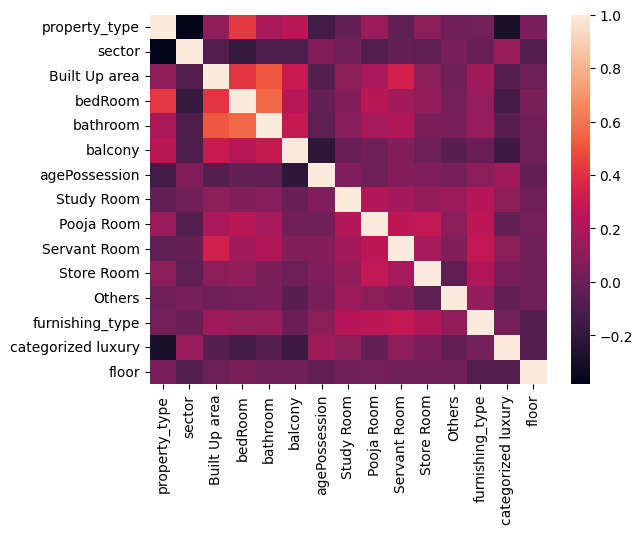

In [23]:
sns.heatmap(x_label.corr())

In [24]:
corr_df = df.corr()['price'].drop('price').to_frame().reset_index().rename(columns={"index":"feature","price":"corr"})
corr_df

,feature,corr
0,property_type,0.281012
1,sector,-0.157593
2,Built Up area,0.669838
3,bedRoom,0.457245
4,bathroom,0.476985
...,...,...
10,Store Room,0.222607
11,Others,-0.016696
12,furnishing_type,0.208467
13,categorized luxury,-0.103589


### Technique-2: Random Forest Feature Importance

In [44]:
#tree based algo has an inbuilt feature to calculate feature importance as it uses them to make tree
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100,random_state=1)
rf.fit(x_label,y_label)
rf_df = pd.DataFrame({
    "feature":x_label.columns,
    "RandomForest feature_importance":rf.feature_importances_
})
rf_df

,feature,RandomForest feature_importance
0,property_type,0.048194
1,sector,0.102600
2,Built Up area,0.620298
3,bedRoom,0.047633
4,bathroom,0.038788
...,...,...
10,Store Room,0.016672
11,Others,0.001711
12,furnishing_type,0.009017
13,categorized luxury,0.005775


### Technique-3: Gradient Boose Feature Importance

In [45]:
#tree based algo has an inbuilt feature to calculate feature importance as it uses them to make tree
from sklearn.ensemble import GradientBoostingRegressor
gbf = GradientBoostingRegressor(n_estimators=100,random_state=1)
gbf.fit(x_label,y_label)
gbf_df = pd.DataFrame({
    "feature":x_label.columns,
    "GradientBoost feature_importance":gbf.feature_importances_
})
gbf_df

,feature,GradientBoost feature_importance
0,property_type,0.061362
1,sector,0.088989
2,Built Up area,0.653349
3,bedRoom,0.046200
4,bathroom,0.046264
...,...,...
10,Store Room,0.005965
11,Others,0.000663
12,furnishing_type,0.005113
13,categorized luxury,0.001053


### Technique 4 - Permutation Importance
###### Isme ek ek feature ko pakadr sirf ussi col ki values ko jumbl up kr dete h and keeping the others same and then compare the accuracy of model before and after . the larger difference shows that higher dependency of col to output and negative shows that accuracy increases after jumbling or kind of independent of that col

In [29]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x_label, y_label, test_size=0.2, random_state=42)

#train data on random forst - prefer tree based because ordinal encoding is used other like linear take 0-1 as weights
rf = RandomForestRegressor(n_estimators=100,random_state=42)
rf.fit(x_train,y_train)

#apply permutation
perm = permutation_importance(rf,x_train,y_train,n_repeats=40,random_state=42)

#organize data
pm = pd.DataFrame({
    'feature':x_train.columns,
    'permutation_importance': perm.importances_mean
}).sort_values(by='permutation_importance', ascending=False)

pm

,feature,permutation_importance
2,Built Up area,1.118160
1,sector,0.152502
3,bedRoom,0.090405
0,property_type,0.081854
4,bathroom,0.070858
...,...,...
8,Pooja Room,0.014023
14,floor,0.008382
12,furnishing_type,0.007533
13,categorized luxury,0.003854


### Technique 5 - LASSO

In [32]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Standardize the features
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x_label)

#lasso
lasso = Lasso(alpha = 0.01,random_state=42)
lasso.fit(x_scaled,y_label)

lasso = pm = pd.DataFrame({
    'feature':x_train.columns,
    'lasso coffecient': lasso.coef_
}).sort_values(by='lasso coffecient', ascending=False)
lasso

,feature,lasso coffecient
2,Built Up area,0.856446
0,property_type,0.224820
8,Pooja Room,0.170765
4,bathroom,0.163407
9,Servant Room,0.152781
...,...,...
1,sector,-0.028131
6,agePossession,-0.032346
13,categorized luxury,-0.051603
14,floor,-0.056688


### Technique 6 - RFE

In [33]:
from sklearn.feature_selection import RFE

# Initialize the base estimator
estimator = RandomForestRegressor()

selector_label = RFE(estimator,n_features_to_select=x_label.shape[1],step=1)
selector_label.fit(x_label,y_label)

# Get the selected features based on RFE
selected_features = x_label.columns[selector_label.support_]

# Extract the coefficients for the selected features from the underlying linear regression model
selected_coefficients = selector_label.estimator_.feature_importances_

# Organize the results into a DataFrame
rfe_model = pd.DataFrame({
    'feature': selected_features,
    'rfe_score': selected_coefficients
}).sort_values(by='rfe_score', ascending=False)

rfe_model

,feature,rfe_score
2,Built Up area,0.618399
1,sector,0.104178
0,property_type,0.047496
3,bedRoom,0.044453
4,bathroom,0.037953
...,...,...
14,floor,0.011139
12,furnishing_type,0.009818
7,Study Room,0.008691
13,categorized luxury,0.006435


### Technique 7 - Linear Regression Weights

In [36]:
# Train a linear regression model on the label-encoded and standardized training data
from sklearn.linear_model import LinearRegression
lin = LinearRegression()
lin.fit(x_scaled, y_label)

# Extract coefficients
lin_reg= pd.DataFrame({
    'feature': x_label.columns,
    'reg_coeffs': lin.coef_
}).sort_values(by='reg_coeffs', ascending=False)

lin_reg

,feature,reg_coeffs
2,Built Up area,0.856032
0,property_type,0.226419
8,Pooja Room,0.173874
4,bathroom,0.166929
9,Servant Room,0.159410
...,...,...
1,sector,-0.034550
6,agePossession,-0.041143
13,categorized luxury,-0.061371
14,floor,-0.068143


### Technique 8 - SHAP

In [37]:
!pip install shap
#used with explanaible ai

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 1.7 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.7 MB/s  0:00:00
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]




[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
import shap

# Compute SHAP values using the trained Random Forest model
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(x_label, y_label)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(x_label)

# Summing the absolute SHAP values across all samples to get an overall measure of feature importance
shap_sum = np.abs(shap_values).mean(axis=0)

shap_values

array([[-6.85393178e-02,  6.96728796e-03, -3.02727022e-02, ...,
        -1.81790867e-02, -3.63634937e-03, -1.39852829e-02],
       [-1.19790809e-01, -1.20572348e-01, -4.81825129e-01, ...,
         4.71872722e-02,  2.32666700e-03,  6.36076471e-03],
       [ 5.81929266e-01, -1.26203624e-01, -2.69205292e-02, ...,
        -8.70744332e-02, -1.63669144e-02, -1.55176378e-02],
       ...,
       [-1.22382658e-01, -4.28572240e-01,  1.25285454e-01, ...,
        -1.96001878e-02, -1.78523191e-03,  1.52165172e-02],
       [ 1.99208464e-01, -7.58510048e-02, -1.24346647e+00, ...,
        -1.34453019e-02,  3.87333316e-04, -8.02396025e-03],
       [-5.59048405e-02, -4.03796850e-02, -5.35548516e-01, ...,
        -7.75217637e-03,  7.43295772e-04,  1.19298174e-03]],
      shape=(934, 15))

In [40]:
shap_model = pd.DataFrame({
    'feature': x_label.columns,
    'SHAP_score': np.abs(shap_values).mean(axis=0)
}).sort_values(by='SHAP_score', ascending=False)

shap_model 

,feature,SHAP_score
2,Built Up area,0.865505
1,sector,0.169429
0,property_type,0.154908
4,bathroom,0.096598
3,bedRoom,0.068834
...,...,...
10,Store Room,0.020082
7,Study Room,0.018151
14,floor,0.014777
13,categorized luxury,0.012575


### Conclusion

In [47]:
 data = corr_df.merge(rf_df,on='feature').merge(gbf_df,on='feature').merge(pm,on='feature').merge(lasso,on='feature').merge(rfe_model,on='feature').merge(lin_reg,on='feature').merge(shap_model,on='feature')

In [73]:
data.head(18)

,feature,corr,RandomForest feature_importance,GradientBoost feature_importance,lasso coffecient_x,lasso coffecient_y,rfe_score,reg_coeffs,SHAP_score
0,property_type,0.281012,0.048194,0.061362,0.224820,0.224820,0.047496,0.226419,0.154908
1,sector,-0.157593,0.102600,0.088989,-0.028131,-0.028131,0.104178,-0.034550,0.169429
2,Built Up area,0.669838,0.620298,0.653349,0.856446,0.856446,0.618399,0.856032,0.865505
3,bedRoom,0.457245,0.047633,0.046200,0.123983,0.123983,0.044453,0.125073,0.068834
4,bathroom,0.476985,0.038788,0.046264,0.163407,0.163407,0.037953,0.166929,0.096598
5,balcony,0.286244,0.021914,0.009687,0.063866,0.063866,0.022947,0.066999,0.027962
6,agePossession,-0.079578,0.029310,0.013289,-0.032346,-0.032346,0.027900,-0.041143,0.035213
7,Study Room,0.191359,0.012103,0.001339,0.142815,0.142815,0.008691,0.152552,0.018151
8,Pooja Room,0.317642,0.018610,0.016514,0.170765,0.170765,0.017069,0.173874,0.023563
9,Servant Room,0.339663,0.018773,0.047845,0.152781,0.152781,0.024296,0.159410,0.033634


In [49]:
data.columns

Index(['feature', 'corr', 'RandomForest feature_importance',
       'GradientBoost feature_importance', 'lasso coffecient_x',
       'lasso coffecient_y', 'rfe_score', 'reg_coeffs', 'SHAP_score'],
      dtype='object')

In [54]:
# Normalization is done to bring numerical features 
# to a comparable scale so that one feature does not dominate another just because its numerical values are larger.


In [72]:
data.set_index('feature')[[
    'corr',
    'RandomForest feature_importance',
    'GradientBoost feature_importance',
    'lasso coffecient_x',
    'lasso coffecient_y',
    'rfe_score',
    'reg_coeffs',
    'SHAP_score'
]].mean(axis=1).sort_values(ascending=False)

feature
Built Up area         0.749539
property_type         0.158629
bathroom              0.148791
bedRoom               0.129675
Servant Room          0.116148
Pooja Room            0.113600
Store Room            0.090897
Study Room            0.083728
balcony               0.070436
furnishing_type       0.045482
sector                0.027099
agePossession        -0.009963
floor                -0.020713
categorized luxury   -0.030291
Others               -0.031357
dtype: float64

### Cross Validation

In [58]:
from sklearn.model_selection import cross_val_score
rf = RandomForestRegressor(n_estimators=100,random_state=42)
score = cross_val_score(rf,x_label,y_label,cv=5,scoring='r2')

In [59]:
score.mean()

np.float64(0.7074373916715408)

In [83]:
score = cross_val_score(rf, x_label.drop(columns=['Pooja Room', 'Others','floor']), y_label, cv=5, scoring='r2')
score.mean()

np.float64(0.706305849741667)

In [84]:
x_label.columns

Index(['property_type', 'sector', 'Built Up area', 'bedRoom', 'bathroom',
       'balcony', 'agePossession', 'Study Room', 'Pooja Room', 'Servant Room',
       'Store Room', 'Others', 'furnishing_type', 'categorized luxury',
       'floor'],
      dtype='object')

### Export

In [85]:
df = df.drop(columns=['Pooja Room', 'Others','floor'])
df.to_csv('Dataset/gurgaon_properties_post_feature_selection.csv', index=False)

In [87]:
df.head(10)

,property_type,sector,price,Built Up area,bedRoom,bathroom,balcony,agePossession,Study Room,Servant Room,Store Room,furnishing_type,categorized luxury
0,0.0,180.0,1.700,1781.139,3,4.0,2.0,2.0,0,0,0,0,1.0
1,0.0,162.0,0.945,1344.108,3,3.0,3.0,2.0,1,0,0,2,2.0
2,1.0,39.0,1.700,2000.040,5,6.0,2.0,0.0,0,0,0,0,1.0
3,0.0,154.0,2.100,1599.950,3,5.0,3.0,2.0,0,1,0,2,2.0
4,0.0,140.0,2.100,1117.577,2,3.0,2.0,2.0,0,0,0,0,1.0
5,0.0,156.0,0.360,546.050,2,3.0,0.0,2.0,0,0,0,0,2.0
6,0.0,83.0,1.300,1703.257,3,4.0,2.0,3.0,0,0,0,0,2.0
7,1.0,75.0,3.500,1345.490,6,7.0,2.0,3.0,0,0,0,0,1.0
8,1.0,48.0,0.380,452.080,2,3.0,0.0,0.0,0,0,0,0,1.0
9,1.0,53.0,1.700,2204.416,1,0.0,1.0,4.0,0,0,0,0,1.0
